In [13]:
import os
from typing import Annotated

from langchain.chat_models import init_chat_model
from langchain_core.tools import tool
from langgraph.graph import START, StateGraph
from langgraph.graph.message import add_messages
from langgraph.prebuilt import ToolNode, tools_condition
from typing_extensions import TypedDict

os.environ["GROQ_API_KEY"] = os.getenv("GROQ_API_KEY")


In [28]:
from dotenv import load_dotenv

load_dotenv()

True

In [29]:
class State(TypedDict):
    # `messages` holds the running conversation as a list. Because it's
    # annotated with `add_messages`, updates to this field are merged by
    # appending the new message(s) onto the existing list rather than
    # replacing the whole list outright.
    messages: Annotated[list, add_messages]

In [30]:
@tool
def get_stock_price(symbol: str) -> float:
    '''Return the current price of a stock given the stock symbol
    :param symbol: stock symbol
    :return: current price of the stock
    '''
    return {
        "MSFT": 200.3,
        "AAPL": 100.4,
        "AMZN": 150.0,
        "RIL": 87.6
    }.get(symbol, 0.0)

tools = [get_stock_price]


llm = init_chat_model("groq:qwen/qwen3.8-27b")
llm_with_tools = llm.bind_tools(tools)

In [31]:
def chatbot(state: State):
    # return {"messages": [llm_with_tools.invoke(state["messages"])]}
    response = llm_with_tools.invoke(state["messages"])  # 1. call the LLM with the history
    return {"messages": [response]}           # 2. return only the new message

builder = StateGraph(State)

builder.add_node(chatbot)
builder.add_node("tools", ToolNode(tools))

builder.add_edge(START, "chatbot")
builder.add_conditional_edges("chatbot", tools_condition)
builder.add_edge("tools", "chatbot")
graph = builder.compile()


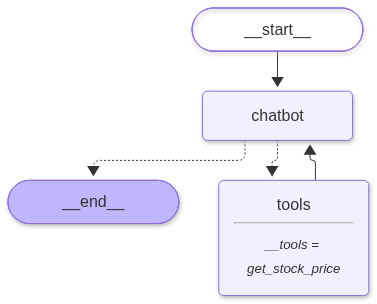

In [32]:
graph

In [33]:
state = graph.invoke({"messages": [{"role": "user", "content": "What is the price of AAPL stock right now?"}]})
print(state["messages"][-1].content)

The current price of AAPL stock is $100.40.


In [34]:
state = graph.invoke({"messages": [{"role": "user", "content": "Who invented theory of relativity? print person name only"}]})
print(state["messages"][-1].content)

Albert Einstein


In [36]:
msg = "I'd like to buy 20 AMZN shares at today's price, plus 15 shares of MSFT. What's the combined total cost?"

state = graph.invoke({"messages": [{"role": "user", "content": msg}]})
print(state["messages"][-1].content)

Here's the breakdown:

- **AMZN**: 20 shares × $150.00 = $3,000.00
- **MSFT**: 15 shares × $200.30 = $3,004.50

**Combined total cost: $6,004.50**


### 🤔 Before you move on
Now the agent can loop — call a tool, see the result, call another tool if needed, then answer. But every `graph.invoke()` call above starts a brand-new conversation with zero memory of the one before it. What if you want the agent to remember earlier turns, like "add it to the previous total"? That's `6_memory.ipynb`.